In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
from scipy.signal import find_peaks


sys.path.insert(0, "cellular_cycle")
sys.path.insert(0, "figures")

import fracprolif as fp

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [5]:
# Setting initial concentrations
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions

,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


2024-09-09 12:52:28.385 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


<Axes: xlabel='Time (h)', ylabel='Concentration'>

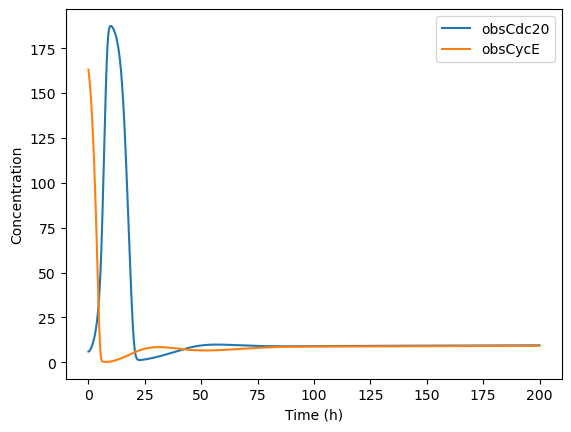

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
model.parameters['CycDi_0'].value = 0.4

sim_ode = ScipyOdeSimulator(model, t, verbose=False).run(); #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)

In [8]:
t = np.linspace(0, 70000, 700001)
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
prot = sim_stoch.run(method='ssa', verbose=False)

<Axes: xlabel='Time (h)', ylabel='Concentration'>

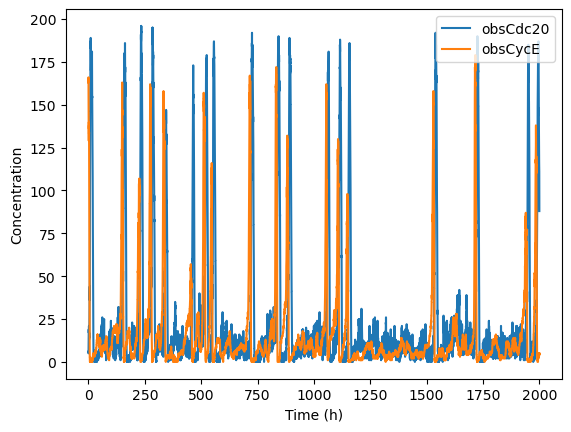

In [9]:
observables=['obsCdc20', 'obsCycE']
plotObs(model=prot.all, obs=observables, times=t, tpos=range(0,20000), legend=True)

In [10]:
def getIMT(prot):
    peaks_cdc, _ = find_peaks(prot.all['obsCdc20'], prominence=100, distance=100)
    IMTs = [t[y] - t[x] for x, y in zip(peaks_cdc, peaks_cdc[1:])]
    
    return IMTs

In [11]:
IMTs = getIMT(prot)

In [12]:
len(IMTs)

518

In [13]:
min(IMTs)

18.399999999997817

In [22]:
init = 10
run_time = 500
observed_cells_time = 500
all_IMTs = []
n = 0

In [23]:
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [24]:
def runIMTs(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, IMTs_count):
    all_IMTs = []
    n = 0
    while len(all_IMTs)<IMTs_count:
        check, population_df, cells, cell_count = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
        all_events_simulated = call_events(run_time, IMT_eoe_counts)
        
        mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()
        mits_list = mits['Lifespan'].tolist()
        mits_list_r = [round(x,1) for x in mits_list]

        IMT_tmp, s_m_tmp, g1_tmp = SMs_G1s_IMTs_extraction(cells)
        
        if n==0:
            all_IMTs = mits_list_r
            all_g1s = g1_tmp
        else:
            all_IMTs.extend(mits_list_r)
            all_g1s.extend(g1_tmp)
        
        # filename_cell_count = Path(SAVE_DIR, f'cell_counts_{condition}_{n}_cycdi_0_4.csv')
        # np.savetxt(filename_cell_count, cell_count, delimiter=',')
        
        n+=1
        print(len(all_IMTs))
        
    # filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_cycdi_500_0_4.csv')
    # filename_g1 = Path(SAVE_DIR, f'G1s_{condition}_cycdi_500_0_4.csv')
    # np.savetxt(filename_IMT, all_IMTs, delimiter=',')
    # np.savetxt(filename_g1, all_g1s, delimiter=',')
    return all_IMTs, all_g1s

In [25]:
all_IMTs, all_g1s = runIMTs(10, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 500)


55 kPa erlotinib
37
55 kPa erlotinib
53
55 kPa erlotinib
92
55 kPa erlotinib
159
55 kPa erlotinib
220
55 kPa erlotinib
280
55 kPa erlotinib
396
55 kPa erlotinib
492
55 kPa erlotinib
546


In [26]:
len(all_IMTs)

546

In [27]:
filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_cycdi_500_0_4.csv')
np.savetxt(filename_IMT, all_IMTs, delimiter=',')

In [28]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian

In [29]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic

In [30]:
from math import log10, floor
def round_sig(x, sig=2):
    return round(x, sig-int(floor(log10(abs(x))))-1)

def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-9
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

# def logl_emg2v2(log_par, data):
#     l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
#     eps = 10e-12
#     return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

def logl_emg2v2(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-12
    temg2 = list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w))
    emg2 = [x + eps for x in temg2]
    ln_em2 = np.log(emg2)
    return ln_em2.sum()

def calc_aicc(AIC, num_params, samp_size):
    aicc = AIC + (2*num_params*(num_params+1)/(samp_size-num_params-1))
    return aicc

def calc_aicp(AICs):
    aicp = [math.exp((min(AICs)-AIC)/2) for AIC in AICs]
    return aicp


def emg_mle_v2(data, log_par, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def emg2_mle_v2(data, log_par2, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def crit(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    
    LL2 = logl_emg2v2(log_par, data)
    negLL2 = -LL2      
    return negLL2

def smooth(y, box_pts):
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    return y_smooth


In [31]:
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

Text(0.015, 75, '$\\mu = 27.34$\n$\\sigma = 7.08$\n$\\lambda = 0.02$')

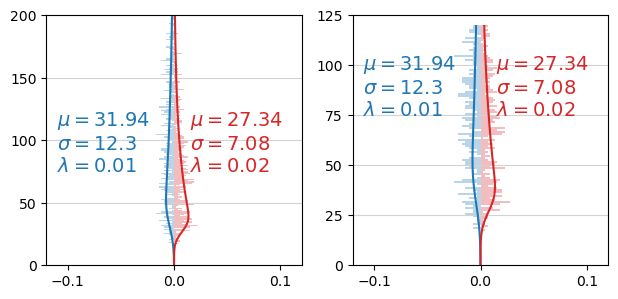

In [32]:
win = 21
pol = 2
size = (7.25,3.25)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 200

fig, axes = plt.subplots(1, 2, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

centers = np.arange(0.5, 200.5, 1)
data = np.array(IMTs)
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,201), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1, size=14)


data = np.array(all_IMTs)
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,201), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2, size=14)

ymin = 0
ymax = 125
centers = np.arange(0.5, 120.5, 1)
data = np.array(IMTs)
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,121), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1, size=14)


data = np.array(all_IMTs)
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,121), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2, size=14)